In [29]:
import torch
import torch.nn as nn
from PIL import Image
from torchvision import transforms, datasets
from torchvision.utils import make_grid
from torch.nn import init
from torch.utils.data import DataLoader, Dataset
from torch.nn.utils.parametrizations import spectral_norm
import matplotlib.pyplot as plt

### Partie 1 : Convolution transposée

1. Chargement de l'image einstein.png et conversion en niveaux de gris de la forme (1,1,H, W) à valeurs dans [0,1]

tensor([[[0.3333, 0.3490, 0.3569,  ..., 0.2431, 0.2471, 0.2392],
         [0.3412, 0.3255, 0.3490,  ..., 0.2627, 0.2627, 0.2588],
         [0.3529, 0.3529, 0.3412,  ..., 0.2863, 0.2902, 0.2824],
         ...,
         [0.1451, 0.1490, 0.1451,  ..., 0.1216, 0.1216, 0.1216],
         [0.1412, 0.1647, 0.1569,  ..., 0.1255, 0.1216, 0.1216],
         [0.1412, 0.1412, 0.1451,  ..., 0.1255, 0.1216, 0.1216]]])
Dimension de la grain: torch.Size([1, 64, 64])


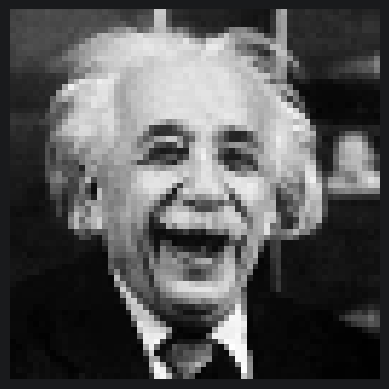

In [2]:
einstein_image = Image.open("einstein.png").convert("L")
transform = transforms.ToTensor()
graine = transform(einstein_image)

print(graine)
print(f"Dimension de la grain: {graine.shape}")

image = graine.squeeze()
plt.imshow(image, cmap="gray")
plt.axis('off')
plt.show()

## 2. Appliquer une convolution transposée 2D, Kernel = 3, Stride = 2 et sans biais et les poids à $\frac{1}{4}$

Dimension de la graine transposée: torch.Size([1, 129, 129])


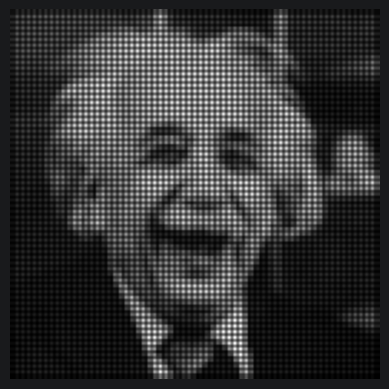

In [3]:
transposed_conv2D = nn.ConvTranspose2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    stride=2,
    bias=False,
)
init.constant_(transposed_conv2D.weight, 1/4)
transposed_graine = transposed_conv2D(graine)
print(f"Dimension de la graine transposée: {transposed_graine.shape}")


img = transposed_graine.detach().squeeze().numpy()
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

## 3. Refaisons l'expérience avec kernel_size = 4, padding=1, en conservant le stride à 2, ainsi que les poids,

Dimension de la graine transposée: torch.Size([1, 128, 128])


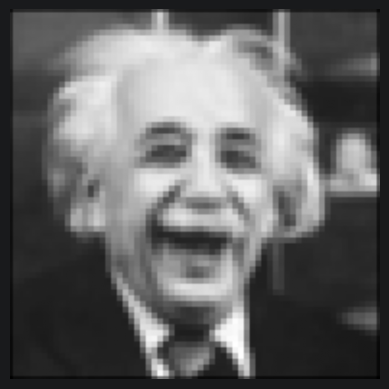

In [4]:
other_transposed_conv2D = nn.ConvTranspose2d(
    in_channels=1,
    out_channels=1,
    kernel_size=4,
    padding=1,
    stride=2,
    bias= False
)

init.constant_(other_transposed_conv2D.weight, 1/4)
other_transposed_graine = other_transposed_conv2D(graine)
print(f"Dimension de la graine transposée: {other_transposed_graine.shape}")

img = other_transposed_graine.detach().squeeze().numpy()
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.show()

## 4. Autre expérience avec un sur échantillonnage suivi d'une convolution classique

Dimension de l'image d'entrée: torch.Size([1, 1, 64, 64])
Dimension de l'image après scaling: torch.Size([1, 1, 128, 128])
Dimension de l'image après scaling et convolution: torch.Size([1, 1, 128, 128])


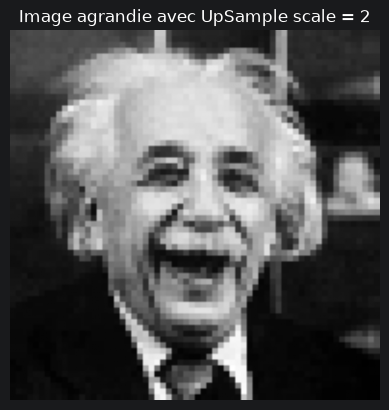

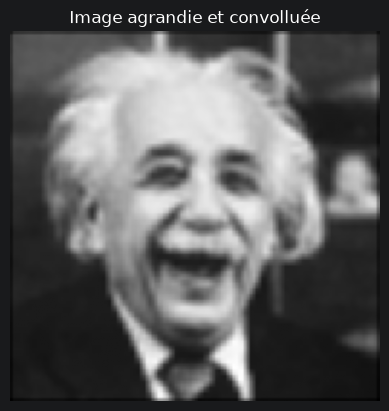

In [5]:
print(f"Dimension de l'image d'entrée: {graine.unsqueeze(0).shape}")
up_sample = nn.Upsample(scale_factor=2)
conv2D = nn.Conv2d(
    in_channels=1,
    out_channels=1,
    kernel_size=3,
    padding=1,
    bias=False
)
init.constant_(conv2D.weight, 1/9)

scaled_image = up_sample(graine.unsqueeze(0))
print(f"Dimension de l'image après scaling: {scaled_image.shape}")
transformed_graine = conv2D(scaled_image)
print(f"Dimension de l'image après scaling et convolution: {transformed_graine.shape}")


scaled_img = scaled_image.detach().squeeze().numpy()
plt.imshow(scaled_img, cmap="gray")
plt.axis("off")
plt.title("Image agrandie avec UpSample scale = 2")
plt.show()

img = transformed_graine.detach().squeeze().numpy()
plt.imshow(img, cmap="gray")
plt.axis("off")
plt.title("Image agrandie et convolluée")
plt.show()

### Partie 2 : DCGAN sur MNIST

Implémentation d'un DCGAN avec PyTorch et l'entrainer sur MNIST (32x32) normalisés dans [-1,1].

Ce GAN est paramétré et nous permettra de mener des expériences.

In [30]:
class Generator(nn.Module):

    def __init__(self, betas: tuple[float, float] = (0.5, 0.999), learning_rate= 2e-4, weight_distribution :tuple[float, float] = (0, 0.02), use_batch_norm: bool = True, base_filter : int = 32, kernel_size=4, stride=2, padding=1, output_padding: int = 0):

        super().__init__()

        self.loss_function = nn.BCEWithLogitsLoss()
        self.weight_distribution = weight_distribution

        # Architecture du réseau
        self.conv_transpose1 = nn.ConvTranspose2d(
            in_channels=100,
            out_channels=base_filter * 2 * 2,
            kernel_size=4,
            stride=1,
            padding=0
        )
        self.batch_norm1 = nn.BatchNorm2d(base_filter * 2 * 2) if use_batch_norm else nn.Identity()
        self.relu1 = nn.ReLU()

        self.conv_transpose2 = nn.ConvTranspose2d(
            in_channels=base_filter * 2 * 2,
            out_channels=base_filter * 2,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            output_padding=output_padding
        )
        self.batch_norm2 = nn.BatchNorm2d(base_filter * 2) if use_batch_norm else nn.Identity()
        self.relu2 = nn.ReLU()

        self.conv_transpose3 = nn.ConvTranspose2d(
            in_channels=base_filter * 2,
            out_channels=base_filter,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            output_padding=output_padding
        )
        self.batch_norm3 = nn.BatchNorm2d(base_filter) if use_batch_norm else nn.Identity()
        self.relu3 = nn.ReLU()

        self.conv_transpose4 = nn.ConvTranspose2d(
            in_channels=base_filter,
            out_channels=1,
            kernel_size=kernel_size,
            stride=stride,
            padding=padding,
            output_padding=output_padding
        )
        self.tanh = nn.Tanh()
        self.optimizer = torch.optim.Adam(
            lr=learning_rate,
            betas=betas,
            params=self.parameters(),
        )


    def init_weights(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
                init.normal_(
                    tensor=module.weight,
                    mean=self.weight_distribution[0],
                    std=self.weight_distribution[1]
                )

    def forward(self, x):
        x = self.relu1(self.batch_norm1(self.conv_transpose1(x)))
        x = self.relu2(self.batch_norm2(self.conv_transpose2(x)))
        x = self.relu3(self.batch_norm3(self.conv_transpose3(x)))
        return self.tanh(self.conv_transpose4(x))






class Discriminator(nn.Module):

    def __init__(self, betas: tuple[float, float] = (0.5, 0.999), learning_rate= 2e-4, weight_distribution :tuple[float, float] = (0, 0.02), base_filter: int = 32, use_spectral_norm: bool = False):
        super().__init__()


        self.loss_function = nn.BCEWithLogitsLoss()
        self.weight_distribution = weight_distribution
        self.use_spectral_norm = use_spectral_norm

        # Architecture du réseau
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=base_filter,
            kernel_size=4,
            stride=2,
            padding=1
        )
        self.leaky_relu1 = nn.LeakyReLU(0.2)

        self.conv2 = nn.Conv2d(
            in_channels=base_filter,
            out_channels=base_filter * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )
        self.batch_norm1 = nn.BatchNorm2d(base_filter * 2)
        self.leaky_relu2 = nn.LeakyReLU(0.2)

        self.conv3 = nn.Conv2d(
            in_channels=base_filter * 2,
            out_channels=base_filter * 2 * 2,
            kernel_size=4,
            stride=2,
            padding=1
        )
        self.batch_norm2 = nn.BatchNorm2d(base_filter * 2 * 2)
        self.leaky_relu3 = nn.LeakyReLU(0.2)

        self.conv4 = nn.Conv2d(
            in_channels=base_filter * 2 * 2,
            out_channels=1,
            kernel_size=4,
            stride=1,
            padding=0
        )

        if self.use_spectral_norm:
            self.conv1 = spectral_norm(self.conv1)
            self.conv2 = spectral_norm(self.conv2)
            self.conv3 = spectral_norm(self.conv3)
            self.conv4 = spectral_norm(self.conv4)

        self.optimizer = torch.optim.Adam(
            lr=learning_rate,
            betas=betas,
            params=self.parameters(),
        )


    def init_weights(self):
        for module in self.modules():
            if isinstance(module, (nn.Conv2d, nn.ConvTranspose2d)):
                if hasattr(module, "parametrizations") and hasattr(module.parametrizations, "weight"):
                    weight = module.parametrizations.weight.original
                else:
                    weight = module.weight
                init.normal_(
                    tensor=weight,
                    mean=self.weight_distribution[0],
                    std=self.weight_distribution[1]
                )



    def forward(self, x):
        x = self.leaky_relu1(self.conv1(x))
        x = self.leaky_relu2(self.batch_norm1(self.conv2(x)))
        x = self.leaky_relu3(self.batch_norm2(self.conv3(x)))
        return self.conv4(x)


    def require_grad(self, activate: bool = True):
        for param in self.parameters():
            param.requires_grad_(activate)





class DcGAN :

    def __init__(self, batch_size : int = 128, epochs: int = 5, eval_every: int = 20, discriminator_lr: float = 2e-4, generator_lr: float = 2e-4, g_betas: tuple[float,float] = (0.5, 0.999), d_betas: tuple[float, float] = (0.5, 0.999), generator_step : int = 1, use_batch_norm_g: bool = True, d_base_filter: int = 32, g_base_filter: int = 32, generator_kernel_size=4, generator_stride=2, generator_padding=1, generator_output_padding: int = 0, real_image_label: float = 1.0, use_spectral_norm: bool = False):


        if generator_step < 1:
            raise ValueError("generator_step doit être supérieur ou égal à 1.")

        if eval_every < 1:
            raise ValueError("eval_every doit être supérieur ou égal à 1.")


        self.batch_size = batch_size
        self.epochs = epochs
        self.generator_step = generator_step
        self.eval_every = eval_every
        self.real_image_label = real_image_label

        # Instanciation du discriminateur et générateur avec initiation des poids
        self.generator = Generator(
            learning_rate=generator_lr,
            betas=g_betas,
            use_batch_norm=use_batch_norm_g,
            base_filter=g_base_filter,
            kernel_size=generator_kernel_size,
            stride=generator_stride,
            padding=generator_padding,
            output_padding=generator_output_padding,
        )
        self.discriminator = Discriminator(
            learning_rate= discriminator_lr,
            betas=d_betas,
            base_filter=d_base_filter,
            use_spectral_norm=use_spectral_norm
        )
        self.generator.init_weights()
        self.discriminator.init_weights()

        # Necessaire pour afficher l'évolution des loss pendant l'entrainement
        self.generators_losses = []
        self.discriminators_losses = []
        self.mean_discriminator_loss = []
        self.mean_generator_loss = []
        self.epoch_boundaries = []
        self.steps = []

        # Graines utiles pour la génération des images pour la validation du générateur.
        self.validation_seed = torch.randn(64,100,1,1)


    def train(self, true_data: Dataset):
        loader = DataLoader(
            dataset=true_data,
            batch_size=self.batch_size,
            shuffle=True,
            drop_last= True
        )
        step = 0
        for epoch in range(self.epochs):
            for (X_mnist, _) in loader:
                step += 1

                # Construction des labels du jeu de données à fournir au discriminateur
                mnist_labels = torch.full(
                    size = (self.batch_size, 1, 1, 1),
                    fill_value=self.real_image_label
                )
                false_mnist_labels = torch.zeros(self.batch_size, 1, 1, 1)


                # Génération des fake images
                seed = torch.randn(self.batch_size,100,1,1)
                X_false_mnist =  self.generator(seed)

                # Passage des vraies et fausses images au discriminateur
                mnist_output = self.discriminator(X_mnist)
                false_mnist_output = self.discriminator(X_false_mnist.detach())

                # Mise à jour des poids du discriminateur
                discriminator_loss = self.discriminator.loss_function(mnist_output, mnist_labels) + self.discriminator.loss_function(false_mnist_output, false_mnist_labels)
                self.discriminator.optimizer.zero_grad()
                discriminator_loss.backward()
                self.discriminator.optimizer.step()


                # Mise à jour des poids du générateur
                generator_loss = None
                self.discriminator.require_grad(False)
                try:
                    for _ in range(self.generator_step):
                        seed = torch.randn(self.batch_size, 100, 1, 1)
                        X_false_mnist = self.generator(seed)

                        output_for_generator = self.discriminator(X_false_mnist)
                        generator_loss = self.generator.loss_function(
                            output_for_generator,
                            torch.ones_like(output_for_generator)
                        )

                        self.generator.optimizer.zero_grad()
                        generator_loss.backward()
                        self.generator.optimizer.step()
                finally:
                    self.discriminator.require_grad(True)



                # Enregistrement des loss
                self.discriminators_losses.append(discriminator_loss.item())
                self.generators_losses.append(generator_loss.item())
                if step % self.eval_every == 0:
                    self.mean_discriminator_loss.append(sum(self.discriminators_losses[-self.eval_every:]) / self.eval_every)
                    self.mean_generator_loss.append(sum(self.generators_losses[-self.eval_every:]) / self.eval_every)
                    self.steps.append(step)

            if epoch < self.epochs - 1:
                self.epoch_boundaries.append(len(self.discriminators_losses))


            # Affichage des images que le générateur génère après un entrainement sur une époque.
            self.generator.eval()
            with torch.no_grad():
                images = self.generator(self.validation_seed)
            self.generator.train()

            grille = make_grid(images, nrow=8, normalize=True)
            plt.imshow(grille.permute(1, 2, 0).cpu())
            plt.axis("off")
            plt.show()



    def plot_losses(self):
        plt.figure(figsize=(12, 7))
        plt.plot(self.steps, self.mean_generator_loss, "o-", label="Generator Loss)")
        plt.plot(self.steps, self.mean_discriminator_loss, "o-", label="Discriminator Loss")

        for boundary in self.epoch_boundaries:
            plt.axvline(x=boundary, linestyle="--", color="gray", alpha=0.5)

        plt.xlabel(f"Itérations (apres chaque {self.eval_every} images)")
        plt.ylabel("Loss")
        plt.title("Evolution de la loss pendant l'entrainement")
        plt.legend()
        plt.show()

In [31]:
# Chargement du dataset MNIST avec un redimensionnement en 32x32 et normalisation des pixels dans [-1, 1] avec la moyenne à 0.
mnist_data = datasets.MNIST(
    root="./data",
    download=True,
    train=True,
    transform=transforms.Compose([
        transforms.Resize(32),
        transforms.ToTensor(),
        transforms.Normalize(mean=0.5, std=0.5)
    ]),
)
image, label = mnist_data[0]
print(f"Forme des données en entrée : {image.shape}")

Forme des données en entrée : torch.Size([1, 32, 32])


## DCGAN standard

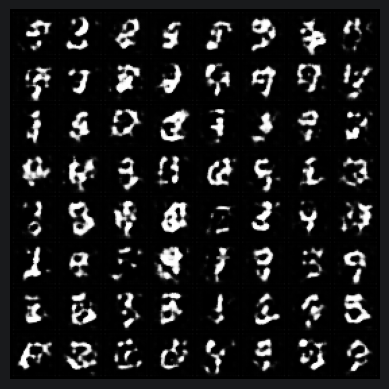

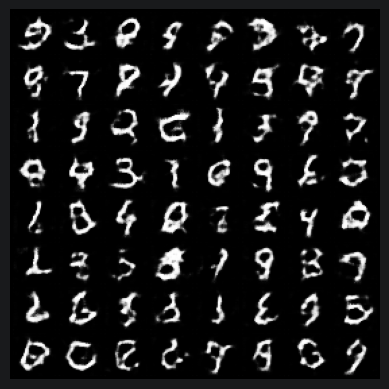

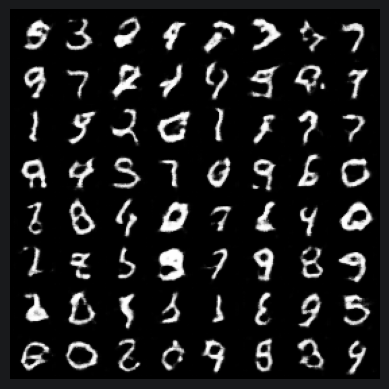

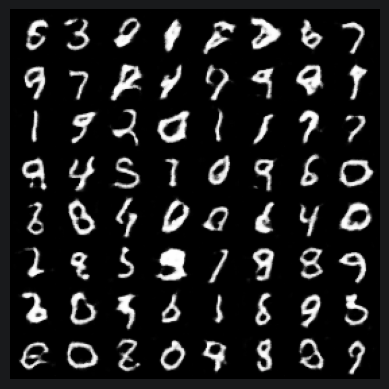

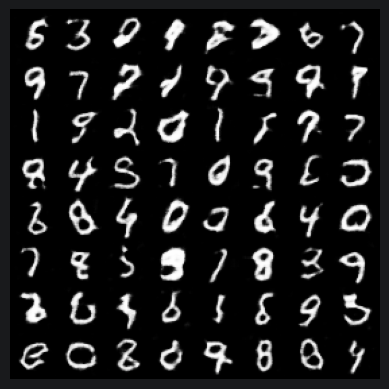

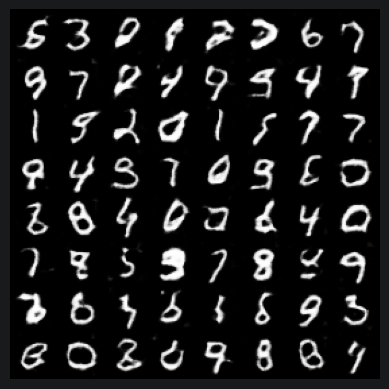

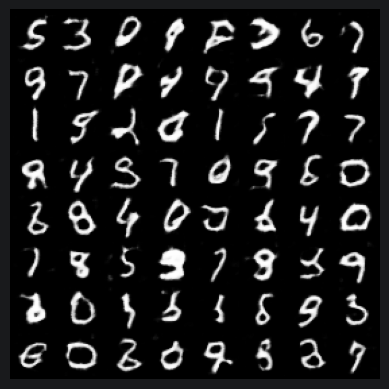

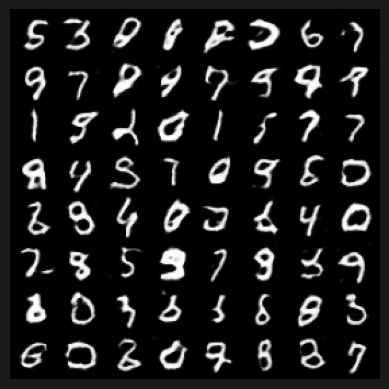

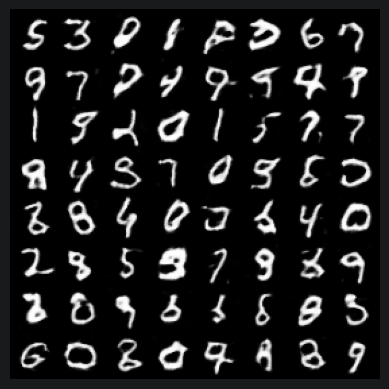

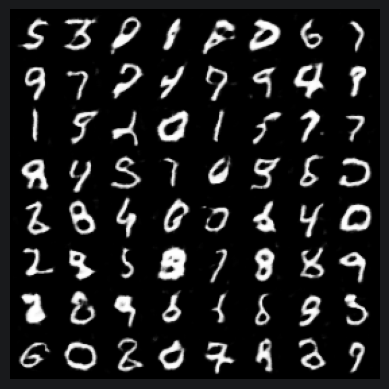

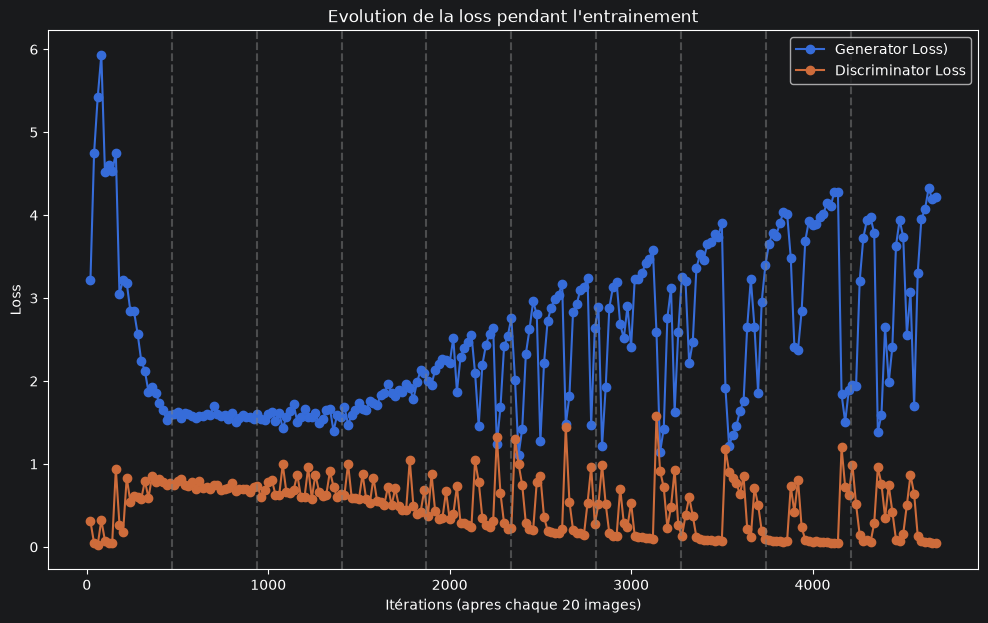

In [32]:
dc_gan = DcGAN(
    batch_size=128,
    epochs=10,
    generator_lr=2e-4,
    g_betas=(0.5, 0.999),
    discriminator_lr=2e-4,
    d_betas=(0.5, 0.999),
)
dc_gan.train(true_data=mnist_data)
dc_gan.plot_losses()

### Partie 3 : Limites des GAN

## 3.1 - Entrainement instable

- Réglage: learning rte de G et D = 2e-3 et leurs betas = (0.9, 0.999)
- Autre variante learning rat de D = 1e-3, de G = 5e-5

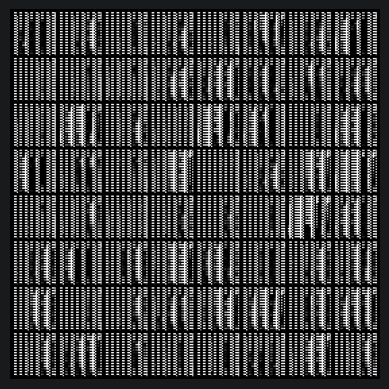

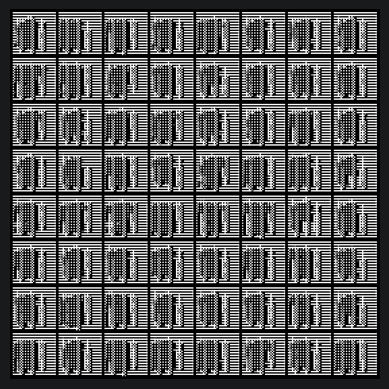

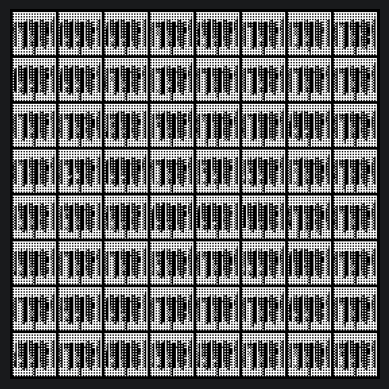

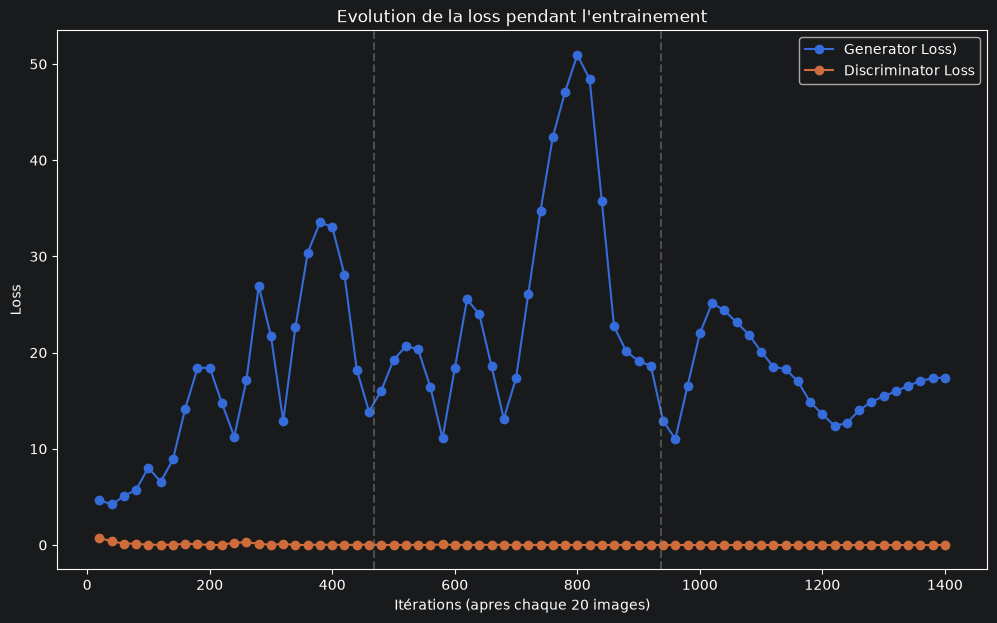

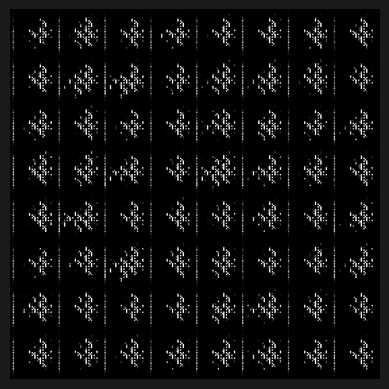

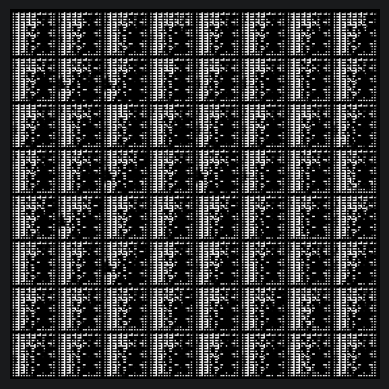

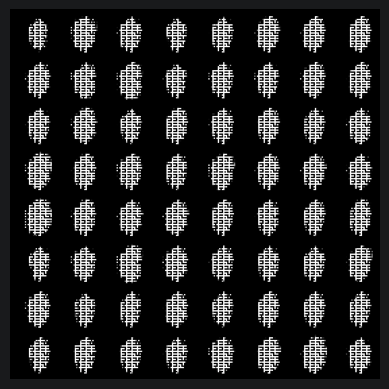

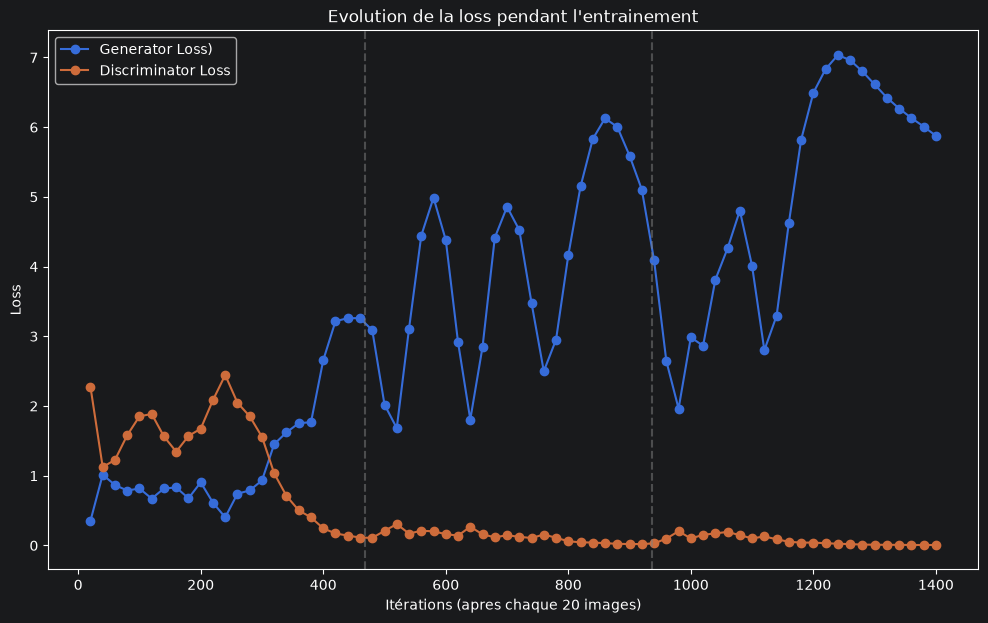

In [34]:
instable_training_model = DcGAN(
    batch_size=128,
    epochs=3,
    generator_lr=2e-3,
    g_betas=(0.99, 0.999),
    discriminator_lr=2e-3,
    d_betas=(0.99, 0.999),
)
instable_training_model.train(true_data=mnist_data)
instable_training_model.plot_losses()


instable_training_model_variant = DcGAN(
    batch_size=128,
    epochs=3,
    generator_lr=1e-3,
    g_betas=(0.99, 0.999),
    discriminator_lr=5e-5,
    d_betas=(0.99, 0.999),
)
instable_training_model_variant.train(true_data=mnist_data)
instable_training_model_variant.plot_losses()

## 3.2 Mode collapse

Réglages:
- pas de BatchNorm dans le générateur et le learning rate du générateur est 1e-3
- Pour une mise à jour du discriminateur, on met à jour le générateur 5 fois.

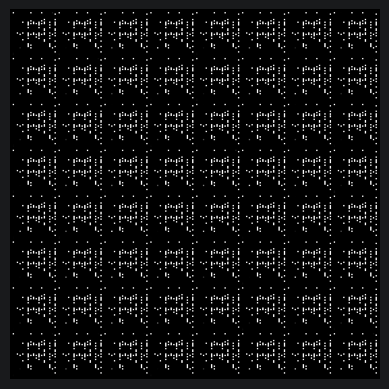

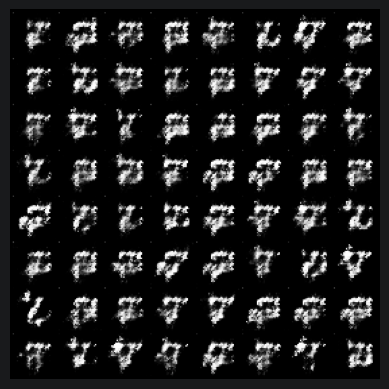

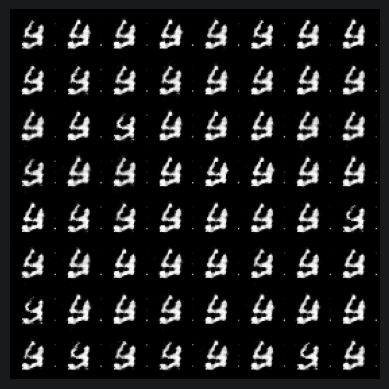

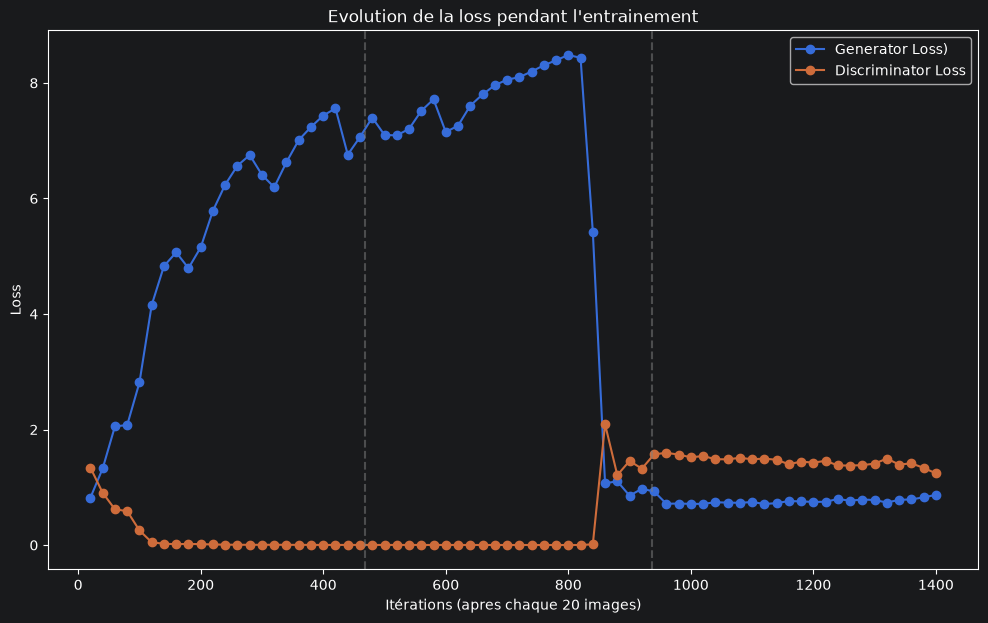

In [35]:
collapse_mode_dc_gan = DcGAN(
    batch_size=128,
    epochs=3,
    generator_lr=1e-3,
    generator_step=5,
    use_batch_norm_g=False
)
collapse_mode_dc_gan.train(true_data=mnist_data)
collapse_mode_dc_gan.plot_losses()

## 3.3 Mauvaise qualité

réglages:
- 8 filtres de base au lieu de 32 dans le générateur comme dans le discriminateur
- convolutions transposées à noyau 3, stride 2, padding 1, et output_padding 1

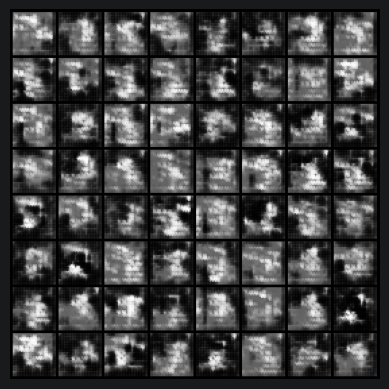

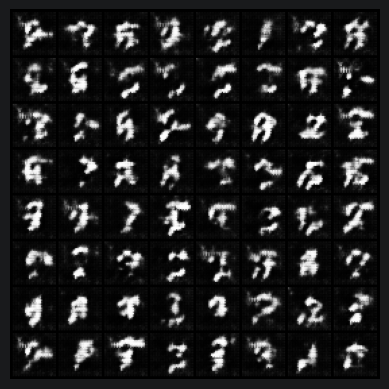

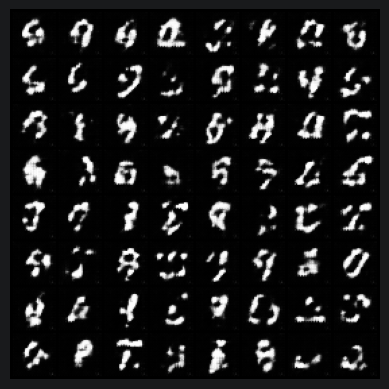

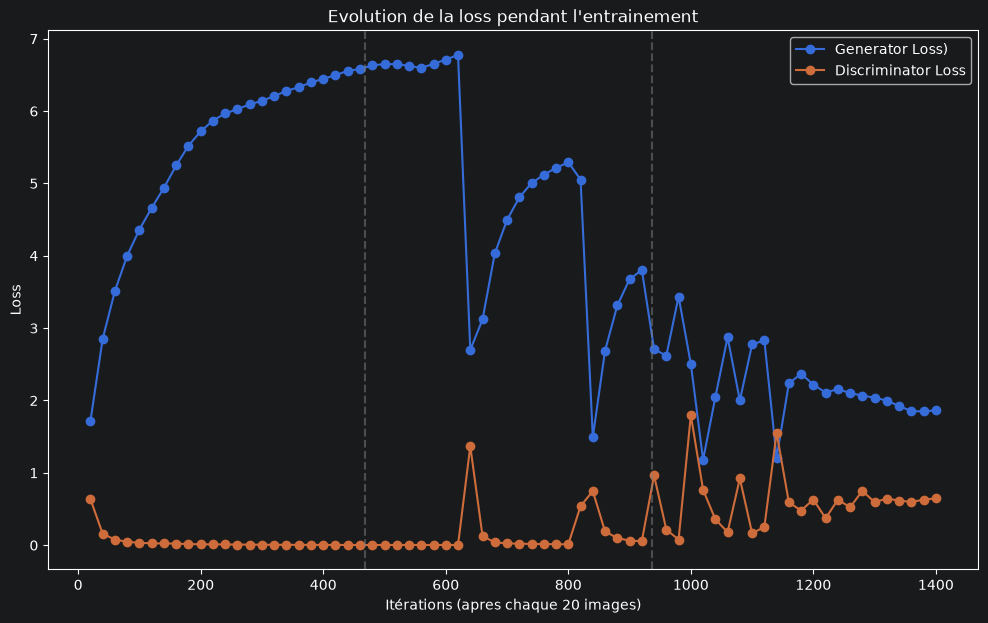

In [36]:
bad_quality_model = DcGAN(
    batch_size=128,
    epochs=3,
    g_base_filter=8,
    generator_kernel_size=3,
    generator_stride=2,
    generator_padding=1,
    generator_output_padding=1,
    d_base_filter=8,
)
bad_quality_model.train(true_data=mnist_data)
bad_quality_model.plot_losses()

## 3.4 Remèdes

- Mettre les labels des vraies images à 0.9
- Rajouter la normalisation spectrale
- Revenir au learning rate à 2e-4 et betas = (0.5, 0.999)

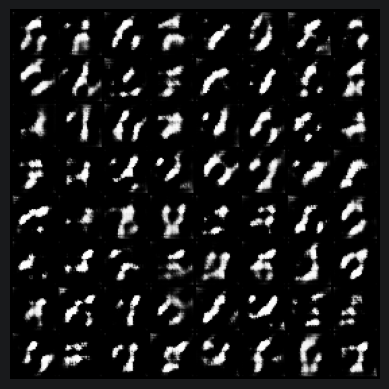

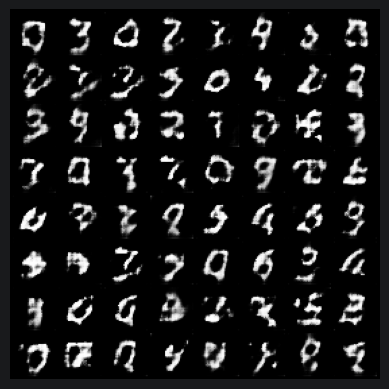

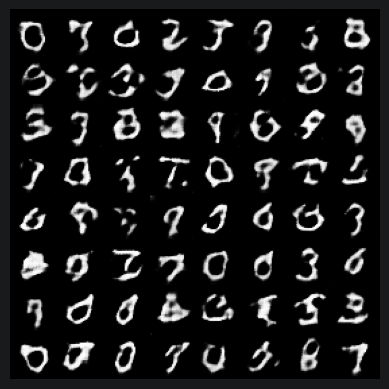

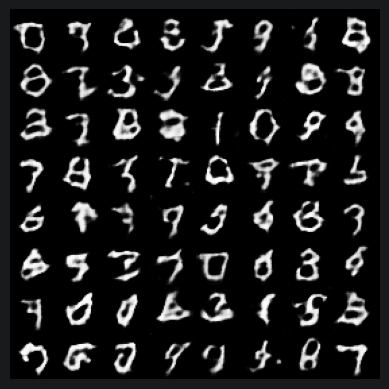

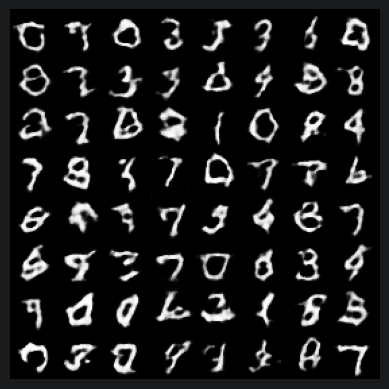

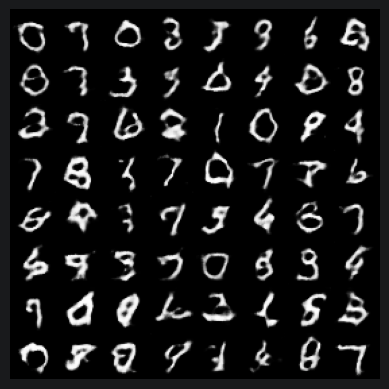

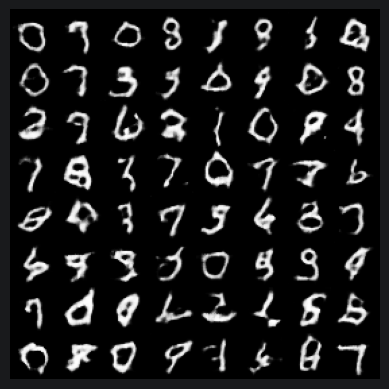

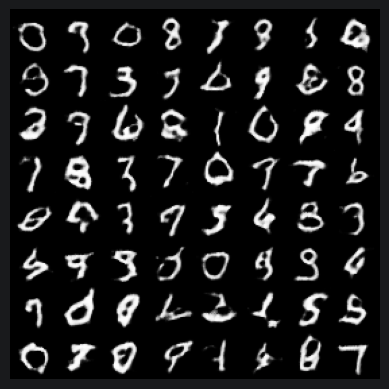

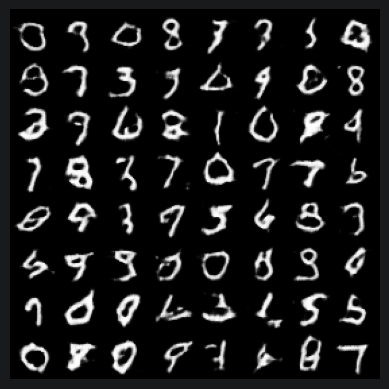

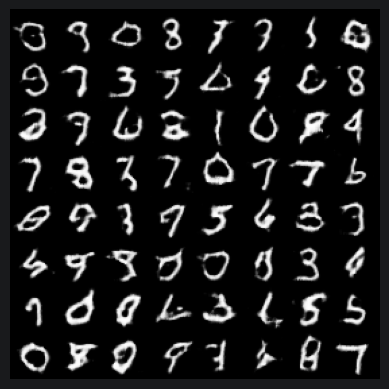

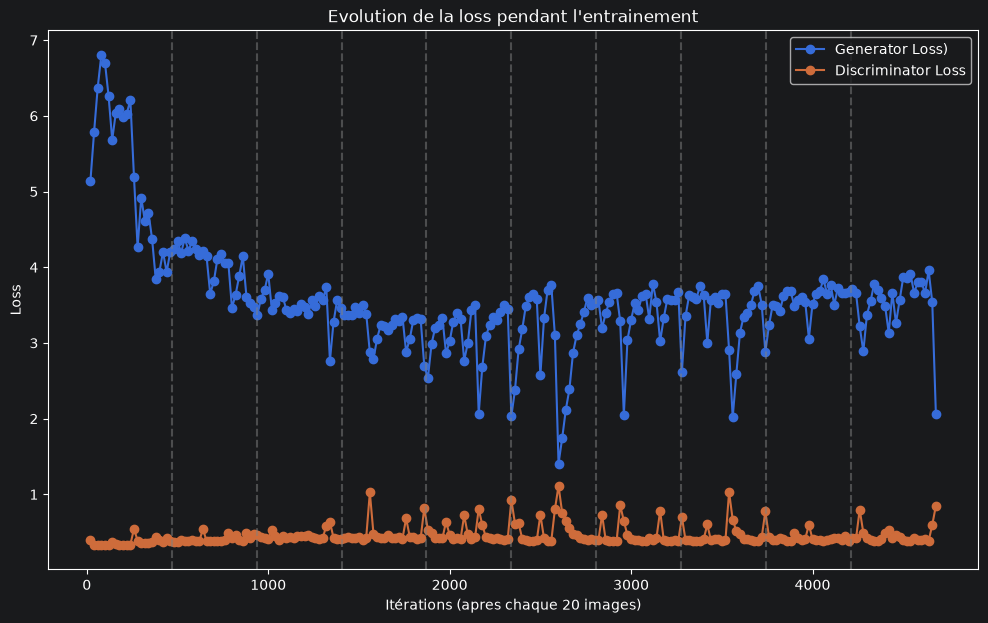

In [38]:
correction_model = DcGAN(
    batch_size=128,
    epochs=10,
    generator_lr=2e-4,
    g_betas=(0.5, 0.999),
    discriminator_lr=2e-4,
    d_betas=(0.5, 0.999),
    real_image_label=0.9,
    use_spectral_norm=True,
    use_batch_norm_g=False
)
correction_model.train(true_data=mnist_data)
correction_model.plot_losses()

### Partie 4: Mini ProGAN

Entrainement d'un GAN qui grandit progressivement sur MNIST : 4x4 ensuite 8x8 ensuite 16x16 et enfin 32x32